In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

dt_ps=0.004

# --- load autocorrelation ---


path="./trj/trj_1/bot/"
df = pd.read_csv( path+"autocorr_avg_norm.csv")

df_LR=pd.read_csv( path+"autocorr_avg_norm_LR.csv")

# species signals
C_stable = {
    "dissociated_OH": df["C_dissociated_OH"].values,
    "remaining_OH": df["C_remaining_OH"].values,
    "C_vac_water": df["C_vac_water"].values,
}

C_unstable = {
    "C_vac_water_down": df["C_vac_water_down"].values,
    "C_vac_water_up": df["C_vac_water_up"].values,
}

C_LR={
    "C_vac_water_right": df_LR["C_vac_water_right"].values,
    "C_vac_water_left": df_LR["C_vac_water_left"].values,
}


def estimate_plateau_excluding_tail(C, exclude_tail_frac=0.5, plateau_frac=0.2):
    """
    Estimate plateau by:
    - discarding the last exclude_tail_frac of the data entirely
    - averaging the last plateau_frac of the *remaining* part
    """

    N = len(C)
    cut = int((1 - exclude_tail_frac) * N)     # endpoint of usable data

    usable = C[:cut]                           # first (1-excl) portion

    start = int((1 - plateau_frac) * len(usable))  # start of plateau window
    plateau_window = usable[start:]

    p = np.mean(plateau_window)
    return p, usable


def subtract_plateau(C,exclude_tail_frac, plateau_frac):
    p, C_cut = estimate_plateau_excluding_tail(C, exclude_tail_frac=0.5, plateau_frac=0.1)
    C_corr = C_cut - p
    C_corr /= 1-p
    return C_corr, p




# --- exponential model ---
def exp1(t, A, tau):
    return A * np.exp(-t / tau)


def fit_and_plot_species(name, t, C_t, t_fit_min, t_fit_max):
    """
    Fit C(t) from t_fit_min up to t_fit_max ps and plot both data + exponential fit.
    """
    # === choose fit window ===
    mask = (t > t_fit_min) & (t < t_fit_max)
    t_fit = t[mask]
    C_fit = C_t[mask]

    # === fit ===
    try:
        popt, pcov = curve_fit(exp1, t_fit, C_fit, p0=(1.0, 1.0), maxfev=5000)
        A_fit, tau_fit = popt
    except RuntimeError:
        print(f"Fit failed for {name}")
        return
    
    print(f"{name}: tau_fit = {tau_fit:.4f} ps   (A={A_fit:.3f})")

    # === generate smooth curve ===
    t_smooth = np.linspace(0, t.max(), 800)
    C_smooth = exp1(t_smooth, A_fit, tau_fit)

    # === plot ===
    plt.figure(figsize=(7,5))
    plt.plot(t, C_t, 'o', ms=3, alpha=0.5, label="data")
    plt.plot(t_smooth, C_smooth, 'r-', lw=2, label=f"fit (tau={tau_fit:.3f} ps)")
    
    
    plt.yscale("log")
    plt.xlabel("τ (ps)")
    plt.ylabel("C(τ)")
    plt.title(f"Autocorrelation: {name}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()



In [68]:
def fit_and_plot_species_linear(name, t, C_t, t_fit_min, t_fit_max):
    """
    Fit log(C(t)) = log(A) - t/tau using linear regression.
    """
    # === choose fit window ===
    mask = (t > t_fit_min) & (t < t_fit_max)
    t_fit = t[mask]
    C_fit = C_t[mask]

    # remove zeros or negative C values (log undefined)
    mask_pos = C_fit > 0
    t_fit = t_fit[mask_pos]
    C_fit = C_fit[mask_pos]

    if len(t_fit) < 5:
        print(f"Not enough data for {name}")
        return

    # === linear fit on log(C) ===
    y = np.log(C_fit)

    # polyfit degree 1: y = m*t + b
    m, b = np.polyfit(t_fit, y, 1)

    tau_fit = -1.0 / m
    A_fit = np.exp(b)

    print(f"{name}: tau_fit = {tau_fit:.4f} ps   (A={A_fit:.3f})")

    # === generate smooth exponential ===
    t_smooth = np.linspace(0, t.max(), 800)
    C_smooth = A_fit * np.exp(-t_smooth / tau_fit)

    # === plot ===
    plt.figure(figsize=(7,5))
    plt.plot(t, C_t, 'o', ms=3, alpha=0.5, label="data")
    plt.plot(t_smooth, C_smooth, 'r-', lw=2,
             label=f"linear-fit (tau={tau_fit:.3f} ps)")

    plt.yscale("log")
    plt.xlabel("τ (ps)")
    plt.ylabel("C(τ)")
    plt.title(f"Autocorrelation: {name}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [69]:
# time spacing: 4 fs = 0.004 ps
dt_ps = 0.004
t =np.arange(len(df)) * dt_ps

N_frame=len(df["C_dissociated_OH"].values)

print('N_frame=',N_frame)
print('time=', N_frame* dt_ps)

N_frame= 348517
time= 1394.068


/tmp/ipykernel_253932/794275553.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


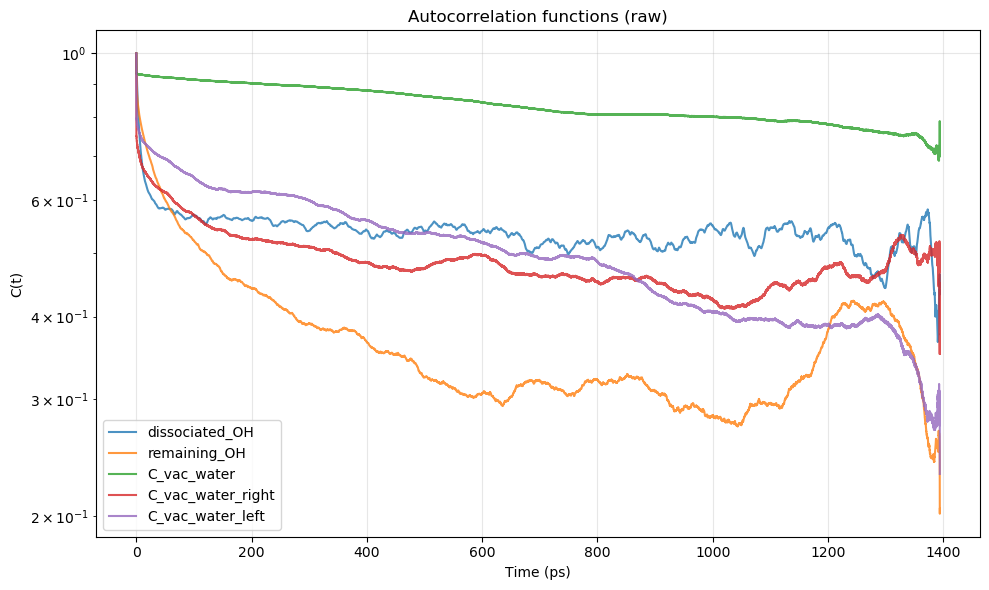

In [70]:
# time spacing: 4 fs = 0.004 ps
dt_ps = 0.004
t = np.arange(len(df)) * dt_ps

max_t=int(1394/dt_ps)


# --- identify all correlation columns automatically ---
corr_cols = [col for col in df.columns if col.startswith("C_")]

plt.figure(figsize=(10,6))


for col, C_t in C_stable.items():
    
    plt.plot(t[:int(max_t)], C_t[:int(max_t)], label=col, alpha=0.8)

for col, C_t in C_LR.items():
    
    plt.plot(t[:int(max_t)], C_t[:int(max_t)], label=col, alpha=0.8)

plt.xlabel("Time (ps)")
plt.ylabel("C(t)")
plt.yscale("log")
plt.title("Autocorrelation functions (raw)")
plt.legend()
plt.grid(alpha=0.3)

plt.xlim()
plt.tight_layout()
plt.show()

In [19]:
C_t

array([1.        , 0.81460679, 0.69064931, ..., 0.11273354, 0.11774249,
       0.13276931])

dissociated_OH: tau_fit = 6402.9949 ps   (A=0.480)


/tmp/ipykernel_253932/405402152.py:46: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


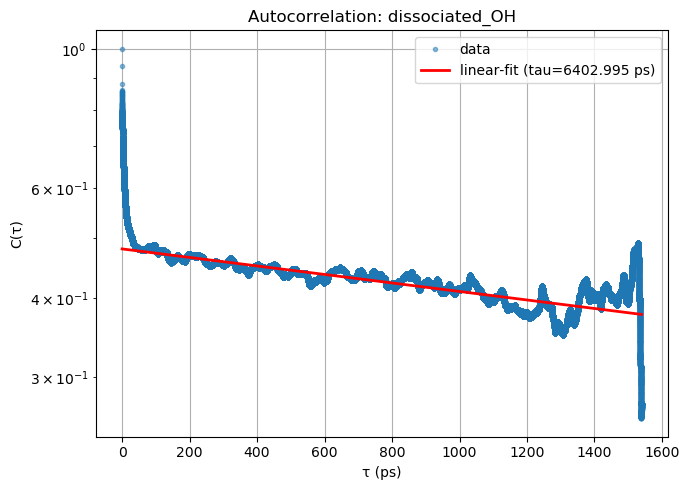

remaining_OH: tau_fit = 2435.9533 ps   (A=0.191)


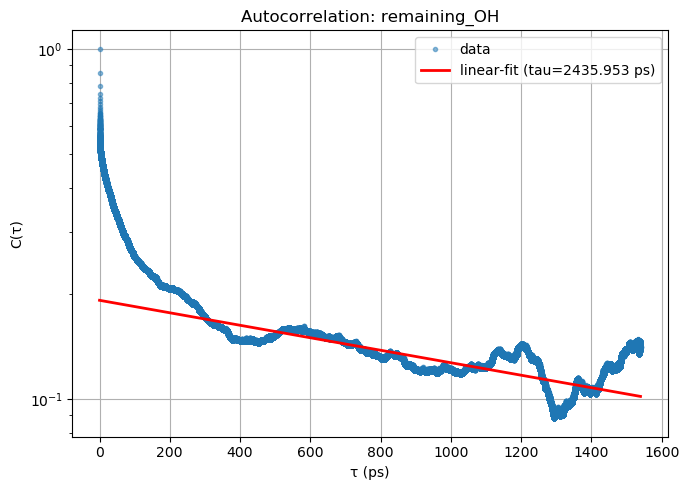

C_vac_water: tau_fit = 1881.8985 ps   (A=0.224)


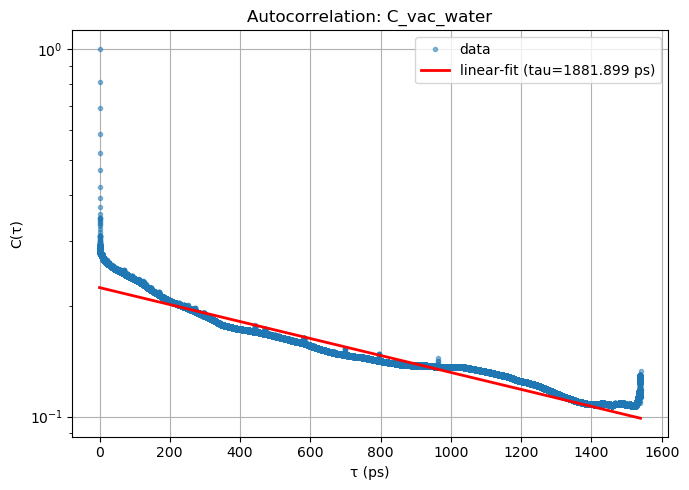

In [20]:
i=0
t_fit_min=[50, 200, 50]
for name, C_t in C_stable.items():
    fit_and_plot_species_linear(name, t,  C_t, t_fit_min=t_fit_min[i], t_fit_max=1200.0)  # adjust 2.0 ps if needed
    i+=1

In [21]:
C_corr = {}
plateaus = {}
exclude_tail_frac=0.5
exclude_tail_frac
plateau_frac=0.1
for sp in C.keys()[:3]:
    
    C_corr[sp], plateaus[sp] = subtract_plateau(C[sp],exclude_tail_frac, plateau_frac)

NameError: name 'C' is not defined